# **FV Solver for the coupled Richards' and heat transport equation**
## Parametrization: Capillary Bundle Model

Author: Anne Hermann   \
anne.hermann@uni-tuebingen.de

In [1]:
import sys
sys.path.append('../../')

import jax.numpy as jnp
from utils.geometry import Geom
from utils import plotting_utils
import utils.parameter_interpolation as inter
import pickle as pkl
import utils.petrophysics_capillaryBundles as petro_cap


An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


### State file and folder names for interpolation and input data

In [2]:
parametrization = "validation"

interp_folder = "../../input/interpolation/"
interp_filename = "interpolation_validation.pkl"

save_folder = "./"
save_file = f"cryorich_AD_output.pkl"

### Mesh Generation

In [3]:
dz = 0.005       # grid spacing [m]
dx = 0.2    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10   # length of the domain [m]
slope = -0.1   # slope of the domain [-]

z_end = 1
z0 = z_end-ztot
geom = Geom(dx, dz, 0, xtot, z0, z_end, slope)  # geometry object

geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  50 x 200 cells.


In [4]:
geom.set_sparsity_pattern()

===============   Calculating coupled sparsity pattern   =============== 
DONE: calculated coupled sparsity pattern with 198000 nonzero entries.


### Time Discretization

In [5]:
dt = 1     # time step [s]
t0 = 0
t_end = 2628000 # end time [s]
maxdt = 1*60*60       # maximum time step [s]
CN = 1          # Crank-Nicolson weighting parameter implicit/explicit
save_t = 657000     # save time [s]
geom.time_discretization(dt, t0, t_end, maxdt,save_t) # time discretization


===============   Creating time discretization   =============== 
DONE: created time discretization.


### Define Soil

In [6]:
# # Sandy soil parameters
soil_type = {1:{}}
soil = jnp.ones((geom.nz,geom.nx))  # soil type array
soil_type[1]["alpha"] = 0.82                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 4.63e-7                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 1.2179                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.01                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.412                      # maximum volumetric water content [-]

#geom.set_vanGenuchten_params(Ksat, alpha, N, Theta_r, Theta_s)

### Interpolation of Hydraulic Parameters:
- interpolate $k_{rel}$ w.r.t. $h_c, T$
- interpolate $\theta_l$ w.r.t. $h_c, T$

In [7]:
# discretize S -> hc
Se = jnp.linspace(1e-6,1,int(5e4)) # effective saturation [-]
#   discretize T
T = jnp.append(jnp.append(jnp.append(jnp.arange(-30,-5,1),jnp.arange(-5,-1,1e-2)),jnp.arange(-1,0,1e-3)),jnp.array([0,10])) # interpolate krel and theta_l for each soil type
#soil_type = inter.interpolate_parameter_drying(Se, T, soil_type, filename=interp_folder+interp_filename_drying, method='monotonic', extrapolate=True)
soil_type = inter.interpolate_parameter(Se, T, soil_type, filename=interp_folder+interp_filename, parametrization=parametrization, method='monotonic', extrapolate=True)

del T,Se

# save interpolated soil type parameters
geom.set_soilType(soil, soil_type)

Loaded interpolated soil type from file:  ../../input/interpolation/interpolation_validation.pkl


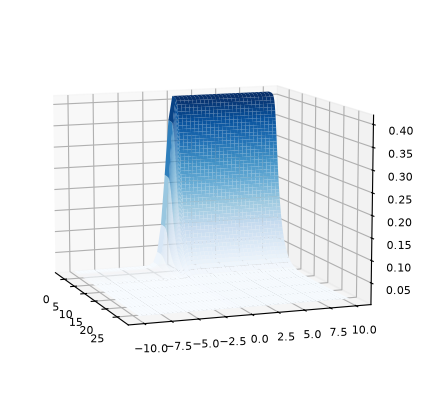

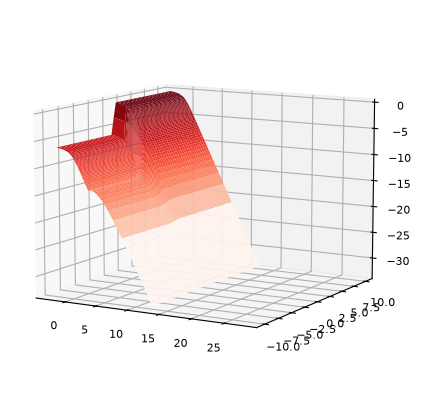

In [8]:
import matplotlib.pyplot as plt
Se = jnp.linspace(1e-6,1,10000)
hc = petro_cap.h_from_S(Se, soil_type[1]["alpha"], soil_type[1]["N"])
T = jnp.linspace(-10,10,1000)

X,Y = jnp.meshgrid(hc, T)
Z = soil_type[1]["theta_l_interp"](X.flatten(), Y.flatten()).reshape(X.shape)

fig, ax = plt.subplots(figsize=(5,5),subplot_kw={"projection": "3d"})
ax.view_init(elev=10, azim=-20, roll=0)
ax.plot_surface(jnp.log10(X),Y,Z, cmap='Blues')

Z = soil_type[1]["k_rel_interp"](X.flatten(), Y.flatten()).reshape(X.shape)
fig, ax = plt.subplots(figsize=(5,5),subplot_kw={"projection": "3d"})
ax.view_init(elev=10, azim=-60, roll=0)
ax.plot_surface(jnp.log10(X),Y,jnp.log10(Z), cmap='Reds')

### Top Boundary Condition

Text(0.5, 0, '$t$ $[d]$')

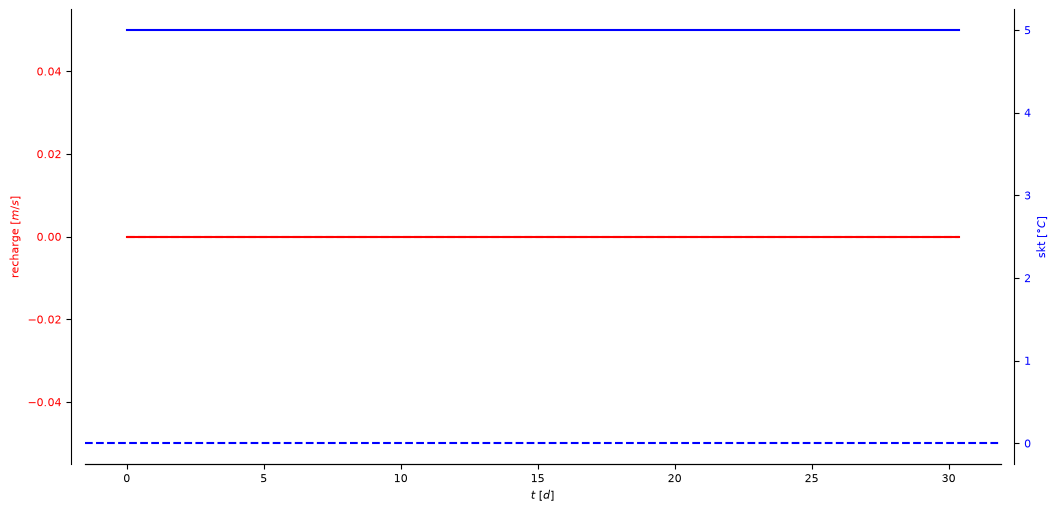

In [9]:
t_bc = jnp.linspace(0, t_end,75) # time points for boundary condition [s]
q_inf = 0*jnp.ones_like(t_bc) # recharge [m/s]

# Smooth (tanh) cooling-then-warming ramp, same envelope as the linear version that already
# separated the five parametrizations (cooling toward day 30-60, warming back through day 90-120),
# just with the corners smoothed out, followed by a hold at T_warm. The hold is needed
# because the ice doesn't clear with the surface warming alone: heat has to diffuse through the
# full 1 m profile and the melt front is latent-heat buffered (zero curtain), which is much
# slower than the surface temperature recovery itself.

T_surface = 5*jnp.ones_like(t_bc)
geom.set_surface_bc(t_bc, q_inf, T_surface,method = "linear")

t_plot = jnp.arange(0, t_end,3600)
cm = 1/2.54
fig, ax = plt.subplots(figsize=(30*cm, 15*cm))
ax.plot(t_plot/24/60/60, geom.q_inf_interp(t_plot), label="recharge", color="red")
ax.set_ylabel("recharge $[m/s]$", color="red")
ax.tick_params(axis="y", labelcolor="red")
ax.plot(t_plot/24/60/60, 0*t_plot, "--",color="red")

ax_cp = ax.twinx()
ax_cp.set_ylabel("skt $[°C]$", color="blue")
ax_cp.plot(t_plot/24/60/60, geom.T_surface_interp(t_plot), label="skt", color="blue")
ax_cp.tick_params(axis="y", labelcolor="blue")
ax_cp.axhline(0, color="blue", linestyle="--")

ax.spines["top"].set_visible(False)
ax_cp.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax_cp.spines["left"].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

ax.set_xlabel("$t$ $[d]$")

### Set Inital Conditions

In [10]:
h_c = 0.8*jnp.ones((geom.nz,geom.nx))
htot = geom.Z-h_c
T_init = (-5*jnp.ones((geom.nz,geom.nx)))
theta_tot = geom.soil_type[1]["theta_l_interp"](h_c.flatten(), abs(T_init).flatten()).reshape(h_c.shape)
theta_l = geom.soil_type[1]["theta_l_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape)
theta_i = theta_tot-theta_l

geom.set_initial_conditions(htot, h_c, theta_l, theta_i, T_init)

===============   Setting initial conditions   =============== 
DONE: set initial conditions.


(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'theta_i'}, xlabel='x [m]', ylabel='z [m]'>)

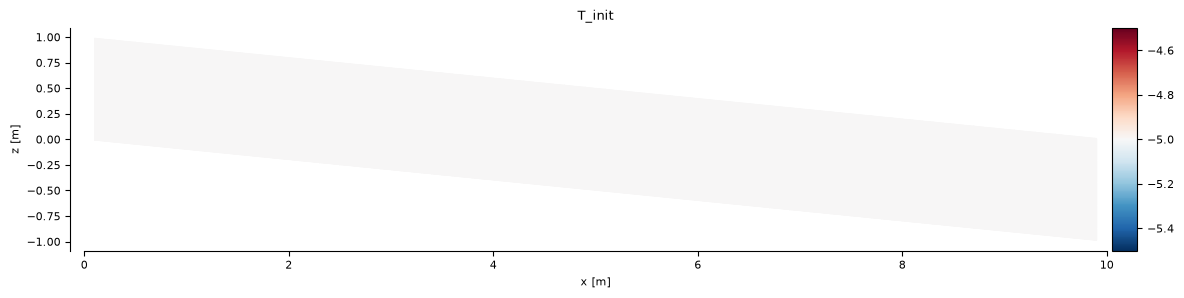

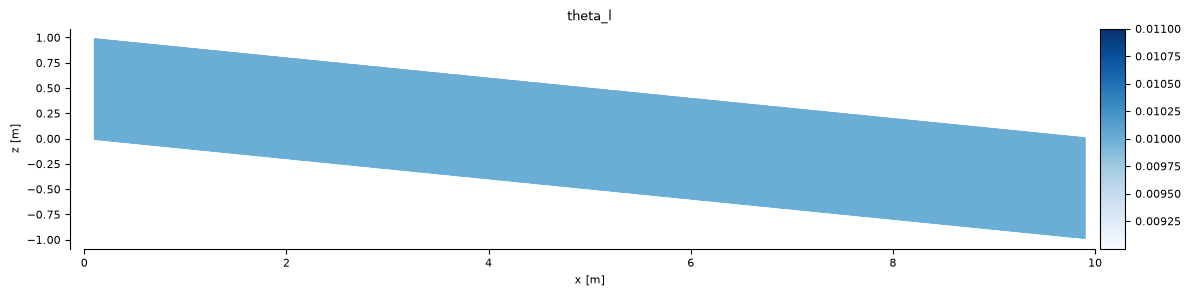

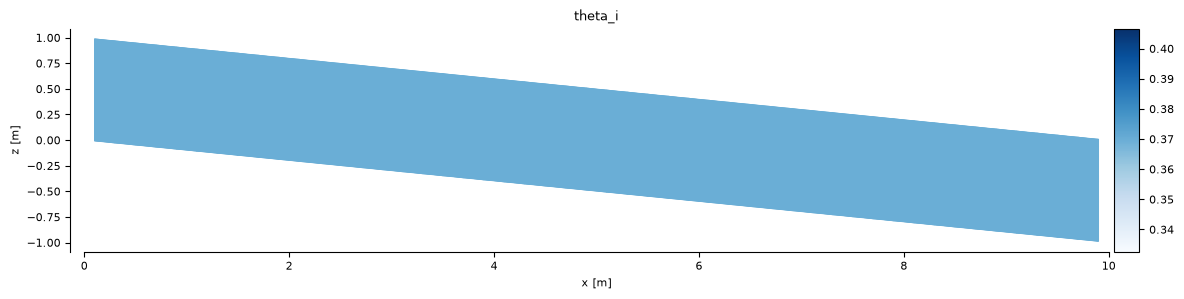

In [11]:
plotting_utils.plot_cellValues(geom.X,geom.Z, T_init,colormap='RdBu_r', title="T_init")
plotting_utils.plot_cellValues(geom.X, geom.Z, geom.theta_l_old, title="theta_l")
plotting_utils.plot_cellValues(geom.X, geom.Z, geom.theta_i_old, title="theta_i")

### Thermal Parameters

In [12]:
rho_l = 998
rho_i = 917
rho_s = 2650
rho_a = 1.1

c_s = 1923720 / rho_s
c_l = 4182000 / rho_l
c_i = 1895200 / rho_i
c_a = 1228.08 / rho_a

lambda_s = 2.9
lambda_l = 0.6
lambda_i = 2.14
lambda_a = 0.0262

H_f = 3.34e8 / rho_i
geom.set_thermal_params(rho_l, rho_i, rho_s, rho_a, c_s, c_l, c_i, c_a, lambda_l, lambda_i, lambda_s, lambda_a,H_f)

### Numerical Parameters

In [13]:
restol_rich=1e-4;      # accepted residual in Newton step
restol_T=1e-4
maxiter=20;      # maxmum number of iterations in Newton step
miniter=5;        # minimum number of iterations in Newton step

geom.set_newton_params(restol_rich,restol_T, maxiter, miniter)

===============   Setting Newton-Raphson parameters   =============== 
Restol: (0.0001, 0.0001)
Max Iterations: 20
Min Iterations: 5
DONE: set Newton-Raphson parameters.


In [14]:
[h_total, h_c_total, theta_l_total,theta_i_total, T_total, q_runoff, qx_array,qz_array,qx_centered_array,qz_centered_array, time_array, iter_total, normres_total]=geom.simulate_cap_bundle()

Starting simulation ...
Time 0.00 d, dt=1.00e+00, NR iterations=3, ||res||_inf=4.471e-01
Time 0.00 d, dt=1.00e+00, NR iterations=3, ||res||_inf=4.766e-01
Time 0.00 d, dt=1.00e+00, NR iterations=3, ||res||_inf=1.261e-02
Time 0.00 d, dt=1.20e+00, NR iterations=4, ||res||_inf=1.190e-02
Time 0.00 d, dt=1.20e+00, NR iterations=4, ||res||_inf=8.953e-03
Time 0.00 d, dt=1.20e+00, NR iterations=3, ||res||_inf=2.439e+01
Time 0.00 d, dt=1.44e+00, NR iterations=3, ||res||_inf=5.085e+00
Time 0.00 d, dt=1.44e+00, NR iterations=3, ||res||_inf=4.574e-01
Time 0.00 d, dt=1.44e+00, NR iterations=3, ||res||_inf=6.497e-02
Time 0.00 d, dt=1.73e+00, NR iterations=3, ||res||_inf=3.999e-02
Time 0.00 d, dt=1.73e+00, NR iterations=3, ||res||_inf=7.516e-03
Time 0.00 d, dt=1.73e+00, NR iterations=3, ||res||_inf=1.827e-03
Time 0.00 d, dt=2.07e+00, NR iterations=3, ||res||_inf=1.544e-03
Time 0.00 d, dt=2.07e+00, NR iterations=3, ||res||_inf=4.219e-04
Time 0.00 d, dt=2.07e+00, NR iterations=3, ||res||_inf=1.178e-04
T

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 't=30.0 days'}, xlabel='x [m]', ylabel='z [m]'>)

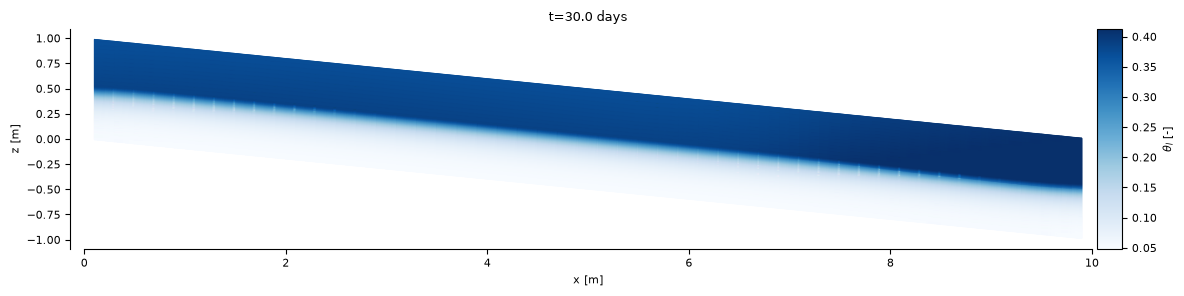

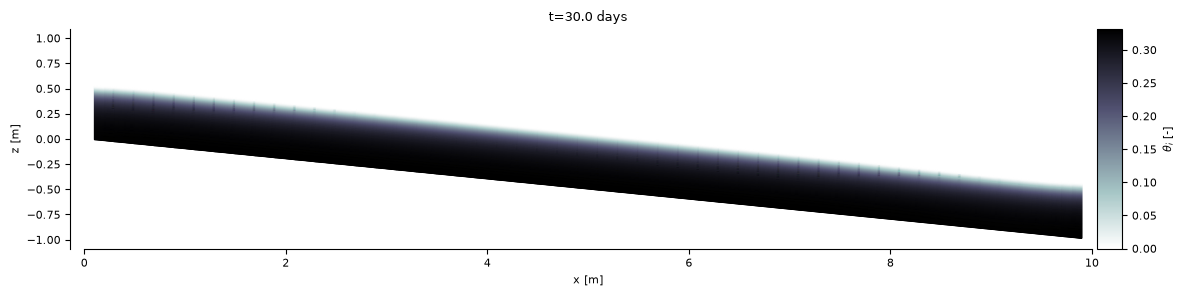

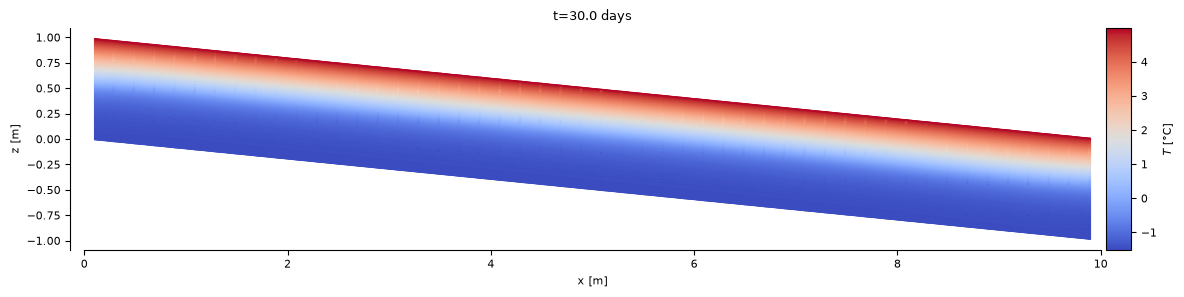

In [15]:
index = -1  # final time step

# plotting_utils.plot_lineProfile(geom, Se, krel, x_position=60, xlabel1=r"$S_e$ [m]", xlabel2=r"$k_{rl}$ [-]")

plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l_total[index], colormap="Blues", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_l$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_i_total[index], colormap="bone_r", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_i$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, T_total[index], colormap="coolwarm", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$T$ [°C]')

In [16]:
# Save simulation output in pickle file
db = {"X": geom.X, "Z":geom.Z,"X_plot":geom.X_plot, "Z_plot":geom.Z_plot, "q_runoff":q_runoff,
      "q_inf_interp":geom.q_inf_interp,"T_surface_interp": geom.T_surface_interp,
      "h_total": h_total, "h_c_total": h_c_total,"theta_l_total":theta_l_total, "theta_i_total":theta_i_total,"T_total": T_total, 
      "qx_array":qx_array,"qz_array":qz_array,"qx_centered_array":qx_centered_array,"qz_centered_array":qz_centered_array,
      "time_array": time_array, "iter_total": iter_total, "normres_total": normres_total}
with open(save_folder + save_file, 'wb') as pickle_file:
    pkl.dump(db, pickle_file)

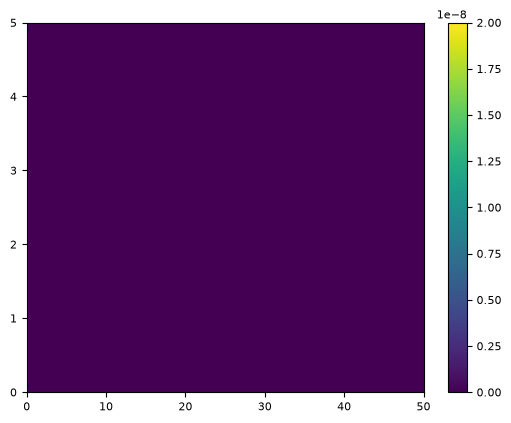

In [17]:
plt.pcolormesh(q_runoff,vmin=0, vmax=2e-8)
plt.colorbar()